In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


Random Forest Training Completed
Bootstrap Sampling: Enabled

Actual values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]

MODEL ACCURACY
Accuracy = 96.67 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


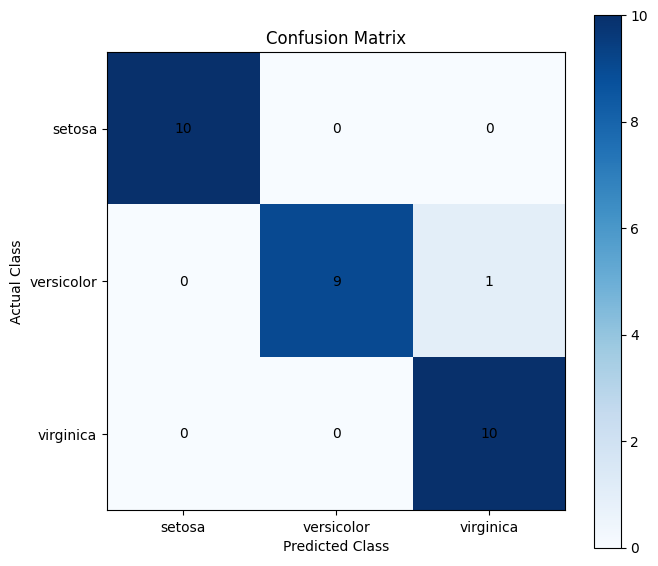

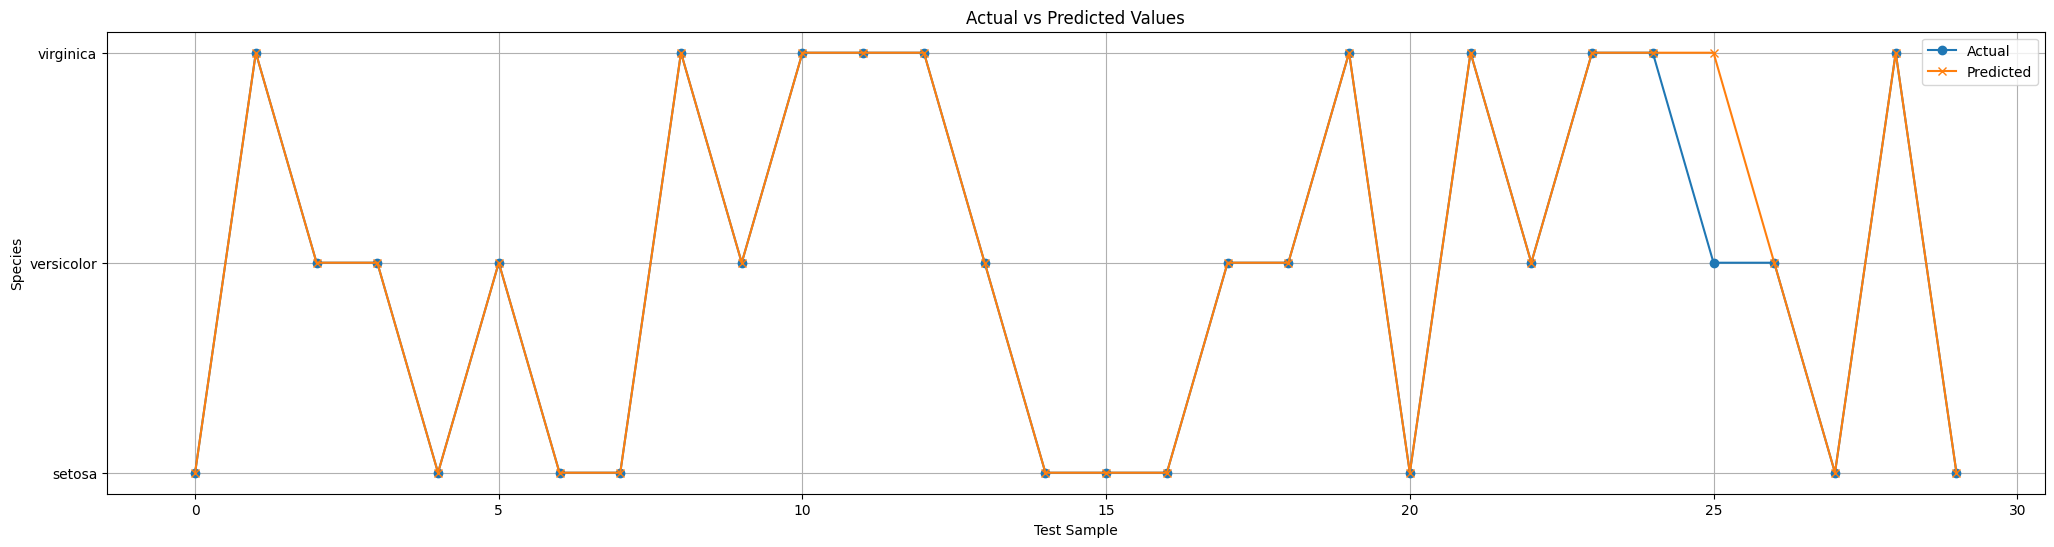


Tree Scores:
[0.9333333333333333, 0.9333333333333333, 0.9333333333333333, 0.9666666666666667, 0.9333333333333333, 0.9333333333333333, 0.9666666666666667, 0.9666666666666667, 0.9666666666666667, 0.9, 0.9, 0.9333333333333333, 0.9, 0.9666666666666667, 0.9, 0.9666666666666667, 0.9, 0.9, 0.9666666666666667, 0.9333333333333333, 0.9333333333333333, 0.9666666666666667, 0.9333333333333333, 0.8666666666666667, 0.9333333333333333, 0.9666666666666667, 0.9333333333333333, 0.8666666666666667, 0.9333333333333333, 0.9666666666666667, 0.8333333333333334, 0.9666666666666667, 0.9333333333333333, 0.9, 0.9, 0.9666666666666667, 0.9, 0.9, 0.9333333333333333, 0.9666666666666667, 0.9333333333333333, 0.9333333333333333, 0.9, 0.9333333333333333, 0.9666666666666667, 0.9333333333333333, 0.9333333333333333, 0.9333333333333333, 0.9, 0.9666666666666667, 0.9333333333333333, 0.9333333333333333, 0.9, 0.8666666666666667, 0.9666666666666667, 0.9333333333333333, 0.9333333333333333, 0.9666666666666667, 0.9666666666666667, 

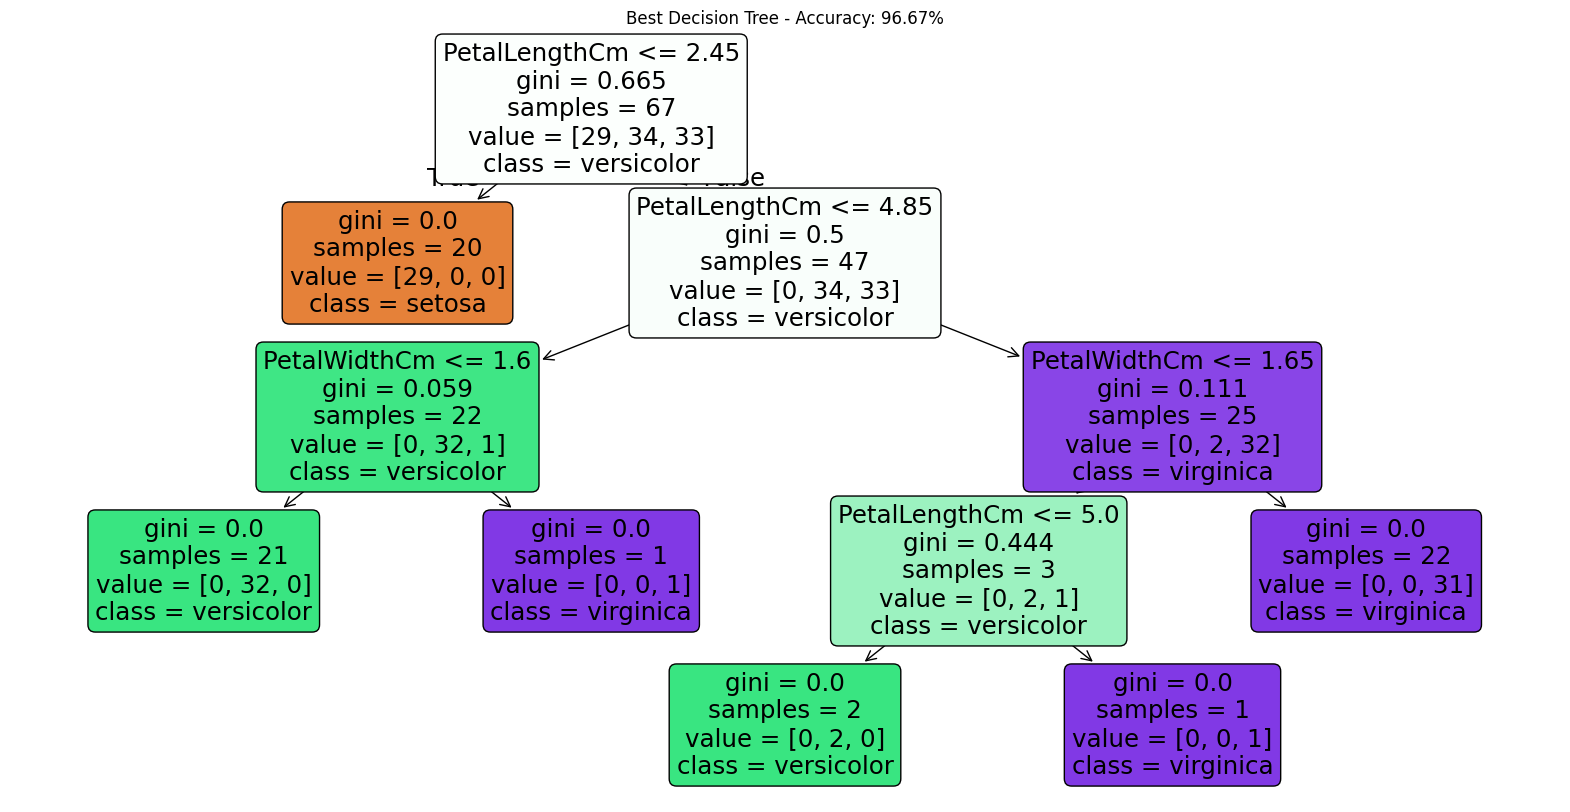

Gradient Boosting Done

Actual values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]

MODEL ACCURACY
Accuracy = 96.67 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


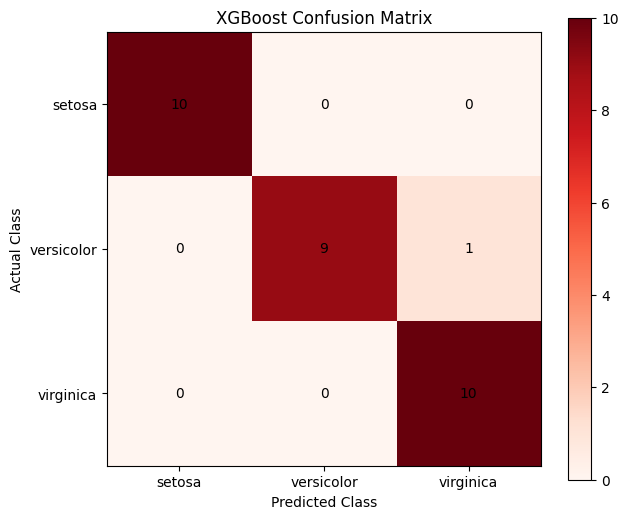

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier
iris=load_iris()
df=pd.DataFrame(iris.data,columns=["SepalLengthCm","SepalWidthCm","PetalLengthCm","PetalWidthCm"])
df["Species"]=iris.target
X = df[
    [
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]
y=df["Species"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

model=RandomForestClassifier(n_estimators=100,criterion="gini",max_depth=4,bootstrap=True,max_samples=0.8,random_state=42)

model.fit(X_train,y_train)
print("\nRandom Forest Training Completed")
print("Bootstrap Sampling: Enabled")
y_pred=model.predict(X_test)
print("\nActual values:")
print(y_test.values)
print("\nPredicted values:")
print(y_pred)
accuracy=accuracy_score(y_test,y_pred)
print("\n"+"="*60)
print("MODEL ACCURACY")
print("="*60)
print("Accuracy =",round(accuracy*100,2),"%")
print("\nClassification Report:")
print(classification_report(y_test,y_pred,target_names=iris.target_names))
cm1=confusion_matrix(y_test,y_pred)
print("\nConfusion Matrix:")
print(cm1)
plt.figure(figsize=(7,6))
plt.imshow(cm1, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(range(len(model.classes_)),iris.target_names)
plt.yticks(range(len(model.classes_)),iris.target_names)
for i in range(len(cm1)):
    for j in range(len(cm1)):
        plt.text(j,i,cm1[i,j],ha="center",va="center")
plt.colorbar()
plt.tight_layout()
plt.show()
plt.figure(figsize=(25,6))
plt.plot(range(len(y_test)),y_test.values,marker="o",label="Actual")
plt.plot(range(len(y_pred)),y_pred,marker="x",label="Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Species")
plt.yticks([0,1,2],iris.target_names)
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(True)
plt.show()
scores=[t.score(X_test.values,y_test) for t in model.estimators_]
best_idx=max(range(len(scores)),key=lambda i:scores[i])
best_tree=model.estimators_[best_idx]
print("\nTree Scores:")
print(scores)
print(f"\nBest Tree: #{best_idx}")
print(f"Best Tree Accuracy: {scores[best_idx]*100:.2f}%")
print("\nBest Tree Rules:")
print(export_text(best_tree,feature_names=list(X_train.columns)))
plt.figure(figsize=(20,10))
tree.plot_tree(best_tree,feature_names=X_train.columns,class_names=iris.target_names,filled=True,rounded=True)
plt.title(f"Best Decision Tree - Accuracy: {scores[best_idx]*100:.2f}%")
plt.show()



gb_model=XGBClassifier(
    n_estimators=100,
    max_depth=4,
    random_state=42,
    eval_metric="mlogloss"
)
gb_model.fit(X_train,y_train)
print("Gradient Boosting Done")
gb_y_pred=gb_model.predict(X_test)
print("\nActual values:")
print(y_test.values)
print("\nPredicted values:")
print(gb_y_pred)
accuracy = accuracy_score(y_test, gb_y_pred)
print("\n" + "=" * 60)
print("MODEL ACCURACY")
print("=" * 60)
print("Accuracy =", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, gb_y_pred))
cm2=confusion_matrix(y_test,gb_y_pred)
print("\nConfusion Matrix:")
print(cm2)
plt.figure(figsize=(7, 6))
plt.imshow(cm2, cmap="Reds")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(range(len(gb_model.classes_)), iris.target_names)
plt.yticks(range(len(gb_model.classes_)), iris.target_names)
for i in range(len(cm2)):
    for j in range(len(cm2)):
        plt.text(j, i, cm2[i, j], ha="center", va="center")
plt.colorbar()
plt.show()   
